# 03 — Classification models and SHAP

Two variations of the same model, trained on the same cleaned data (`src/prep.py`) and the same split:

| Model | Target | Question it answers |
|---|---|---|
| **A. Binary** | 1 = bought PA or life, 0 = rejected | *Who will buy anything?* |
| **B. 3-class** | 0 = rejected, 1 = PA, 2 = life | *Who will buy, and which product?* |

**Algorithm:** LightGBM (gradient-boosted decision trees). It handles missing values and categories natively, captures non-linear effects (e.g. the MOB curve) without hand-made bands, and SHAP (SHapley Additive exPlanations) can explain it exactly with `TreeExplainer`.
A **logistic regression** on the same features is the baseline: if boosting can't beat it, the simpler model wins.

**Imbalance (1.2% buy).** Every model is class-weighted with weight = (majority count) ÷ (class count), taken from the training rows:
- binary LightGBM: `scale_pos_weight` = rejected ÷ buyers;
- 3-class LightGBM: the same ratio as per-row weights, since `scale_pos_weight` only exists for binary;
- logistic regression: `class_weight`.

Early stopping uses the validation loss weighted the same way. An unweighted LightGBM is kept next to each one for comparison. There is no SMOTE or undersampling and no hyperparameter tuning.

**How the models are judged.** Only 1.2% of customers buy, so accuracy is useless (predicting "reject" for everyone is 98.8% accurate). The use case is *ranking customers for a campaign*, so the metrics are:
- **PR AUC** (Precision-Recall Area Under the Curve, computed as average precision): the main metric. It only looks at how precise the model is on the buyers it finds, so the 98.8% easy rejecters can't inflate it (ROC AUC, the usual alternative, can look good on data this imbalanced while precision stays poor).
  A random ranking scores PR AUC = the base rate, so every PR AUC is shown next to **PR AUC ÷ base rate** ("how many times better than random").
- **Lift and capture in the top 10% / 20%**: if we only call the top-scored 10%, how many times the average rate do we hit, and what share of all buyers do we reach? This is PR AUC translated into campaign terms.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score
from src import prep

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "font.family": "sans-serif"})
PA, LIFE, GREY, INK = "#2a78d6", "#eb6834", "#898781", "#0b0b0b"
SEED = 42

df, _ = prep.load_clean()
print(f"{len(df):,} customers, acceptance {df['accepted'].mean():.2%}")

214,053 customers, acceptance 1.22%


## 1. Features

The model uses the customer's raw fields after cleaning, not the bands from notebook 02 (trees find their own cut-points).

**Left out on purpose:**
- `campaign_month`: there is no year, so the model would learn "Jul was a good month", which can't be used to score a future campaign.
- the dropped columns (15-day copies, `currentacc_bal`) and every field derived from `label`.

MOB 0 rows are kept as they are (see notebook 01 / README note). A tree can still learn that MOB 0 behaves differently from MOB 1–12.

In [2]:
NUM = ["age", "income", "num_children", "mob", "easypymt_last_30d", "savacc_bal", "avg_savaccbal_30d",
       "avg_currentaccbal_30d", "maxosdc_last_30d", "dcspend_last_30d", "inflow30d", "outflow30d", "net_flow_30d"]
CAT = ["gender", "marital", "main_occupation", "customer_segment", "have_cc", "have_acc_planet", "scb_payroll"]
FEATURES = NUM + CAT

X = df[FEATURES].copy()
for c in CAT:
    X[c] = X[c].astype("category")
y_bin = df["accepted"].to_numpy()
y_3 = df["label"].astype(int).to_numpy()

# One split for both models: 60% train, 20% validation (early stopping), 20% test (reported).
# Stratified on the 3-class label, so PA and life keep their shares in every part.
idx = np.arange(len(df))
i_train, i_rest = train_test_split(idx, test_size=0.4, stratify=y_3, random_state=SEED)
i_valid, i_test = train_test_split(i_rest, test_size=0.5, stratify=y_3[i_rest], random_state=SEED)
split = pd.DataFrame({"rows": [len(i_train), len(i_valid), len(i_test)],
                      "PA": [(y_3[i] == 1).sum() for i in (i_train, i_valid, i_test)],
                      "Life": [(y_3[i] == 2).sum() for i in (i_train, i_valid, i_test)]},
                     index=["train", "valid", "test"])
split

,rows,PA,Life
train,128431,980,593
valid,42811,327,198
test,42811,327,197


In [3]:
# Deliberately conservative settings: shallow trees, large leaves, so the model can't memorise ~1,500 training buyers.
PARAMS = dict(n_estimators=2000, learning_rate=0.03, num_leaves=15, min_child_samples=200,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              random_state=SEED, verbose=-1)

def class_weights(y):
    # Each class weighted by (majority count) / (its count), from the training rows only. Rejected = 1.
    counts = np.bincount(y[i_train])
    return counts.max() / counts

def fit_lgb(y, objective, weighted=True):
    w = class_weights(y) if weighted else np.ones(y.max() + 1)
    extra = {}
    if objective == "binary":
        extra["scale_pos_weight"] = w[1]           # = rejected / buyers in the training set
        fit_w = None
    else:
        fit_w = w[y[i_train]]                      # multiclass has no scale_pos_weight: same ratio as per-row weights
    model = lgb.LGBMClassifier(objective=objective, **PARAMS, **extra)
    # Early stopping on the validation loss weighted the same way, so training and stopping optimise the same thing.
    model.fit(X.iloc[i_train], y[i_train], sample_weight=fit_w,
              eval_set=[(X.iloc[i_valid], y[i_valid])], eval_sample_weight=[w[y[i_valid]]],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

# Logistic-regression baseline on the same features: log-transform money, one-hot categories.
signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")
def fit_logit(y):
    pre = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), signed_log, StandardScaler()), NUM),
        (make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"), OneHotEncoder(handle_unknown="ignore", min_frequency=200)), CAT))
    Xs = X.copy()
    for c in CAT:
        Xs[c] = Xs[c].astype(object)
    w = class_weights(y)
    model = make_pipeline(pre, LogisticRegression(max_iter=2000, C=1.0, class_weight=dict(enumerate(w))))
    model.fit(Xs.iloc[i_train], y[i_train])
    return model, Xs

def lift_table(y_true, score, tops=(0.05, 0.10, 0.20, 0.30)):
    order = np.argsort(-score)
    y_sorted = np.asarray(y_true)[order]
    rows = []
    for q in tops:
        k = int(len(y_sorted) * q)
        rows.append({"top": f"{q:.0%}", "precision %": y_sorted[:k].mean() * 100,
                     "lift": y_sorted[:k].mean() / y_sorted.mean(),
                     "recall %": y_sorted[:k].sum() / y_sorted.sum() * 100})
    return pd.DataFrame(rows).set_index("top").round(2)

## 2. Model A — binary (bought anything vs rejected)

In [4]:
lgb_bin = fit_lgb(y_bin, "binary")                         # scale_pos_weight = rejected / buyers
lgb_bin_raw = fit_lgb(y_bin, "binary", weighted=False)     # for comparison only
logit_bin, Xs = fit_logit(y_bin)
yt = y_bin[i_test]
p_lgb = lgb_bin.predict_proba(X.iloc[i_test])[:, 1]
p_raw = lgb_bin_raw.predict_proba(X.iloc[i_test])[:, 1]
p_log = logit_bin.predict_proba(Xs.iloc[i_test])[:, 1]
print("scale_pos_weight = %.1f" % class_weights(y_bin)[1])
print("trees used (early stopping): weighted %d, unweighted %d" % (lgb_bin.best_iteration_, lgb_bin_raw.best_iteration_))
def pr_row(y_true, score):
    ap = average_precision_score(y_true, score)
    return {"base rate %": np.mean(y_true) * 100, "PR AUC %": ap * 100, "× random": ap / np.mean(y_true)}

res_bin = pd.DataFrame({"Random": {"base rate %": yt.mean() * 100, "PR AUC %": yt.mean() * 100, "× random": 1.0},
                        "Logistic regression (class-weighted)": pr_row(yt, p_log),
                        "LightGBM, unweighted": pr_row(yt, p_raw),
                        "LightGBM, scale_pos_weight": pr_row(yt, p_lgb)}).T.round(2)
res_bin

scale_pos_weight = 80.6
trees used (early stopping): weighted 144, unweighted 278


,base rate %,PR AUC %,× random
Random,1.22,1.22,1.00
Logistic regression (class-weighted),1.22,2.21,1.81
"LightGBM, unweighted",1.22,2.67,2.18
"LightGBM, scale_pos_weight",1.22,2.59,2.11


In [5]:
# Train vs validation vs test PR AUC: a large gap would mean overfitting.
print("LightGBM PR AUC  train %.2f%% | valid %.2f%% | test %.2f%%" % tuple(
    100 * average_precision_score(y_bin[i], lgb_bin.predict_proba(X.iloc[i])[:, 1]) for i in (i_train, i_valid, i_test)))
lift_table(yt, p_lgb)

LightGBM PR AUC  train 4.52% | valid 2.82% | test 2.59%


,precision %,lift,recall %
top,,,
5%,3.46,2.83,14.12
10%,3.22,2.63,26.34
20%,2.74,2.24,44.85
30%,2.31,1.89,56.68


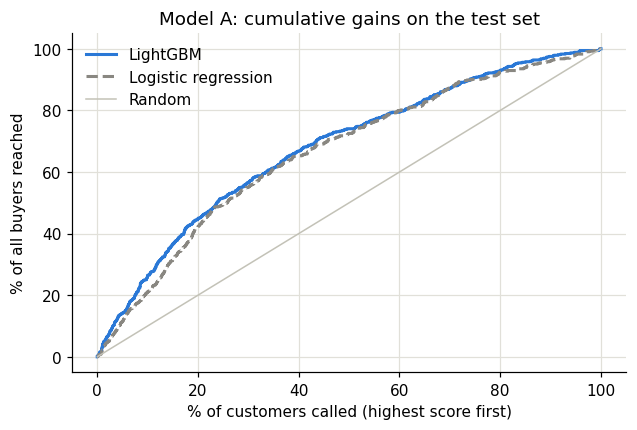

In [6]:
# Cumulative gains: share of all buyers reached when calling the top x% of customers by score.
def gains(ax, y_true, score, label, color, ls="-"):
    order = np.argsort(-score)
    cum = np.cumsum(np.asarray(y_true)[order]) / np.sum(y_true)
    x = np.arange(1, len(cum) + 1) / len(cum)
    ax.plot(x * 100, cum * 100, color=color, lw=2, ls=ls, label=label)

fig, ax = plt.subplots(figsize=(6.5, 4))
gains(ax, yt, p_lgb, "LightGBM", PA)
gains(ax, yt, p_log, "Logistic regression", GREY, "--")
ax.plot([0, 100], [0, 100], color="#c3c2b7", lw=1, label="Random")
ax.set_xlabel("% of customers called (highest score first)"); ax.set_ylabel("% of all buyers reached")
ax.set_title("Model A: cumulative gains on the test set"); ax.legend(frameon=False)
plt.show()

**Model A results** (LightGBM with `scale_pos_weight` = rejected ÷ buyers in the training set = 80.6)
- **Weighting barely changes the ranking.** Test PR AUC is 2.59% (2.1× random) with `scale_pos_weight`, against 2.67% (2.2×) without it. Class-weighted logistic regression reaches 2.21% (1.8×).
  This is expected: the weight multiplies every buyer's contribution by the same constant, which shifts all scores up (probabilities become inflated) but changes the *order* of customers only a little. PR AUC only measures order.
- **It does reduce overfitting.** Train PR AUC falls from 12.2% (unweighted) to 4.5%, against 2.8% on validation and 2.6% on test. The weighted validation loss stops early (144 trees instead of 278), so the model memorises less.
- **In campaign terms**, the top 10% of scores has **precision 3.2%** (2.6× lift) and **recall 26%**. The top 20% reaches recall 45%.
- **Why the ceiling is low.** It matches notebook 02 (pseudo R² 0.06): these fields only explain part of who buys.

## 3. Model B — 3 classes (rejected / PA / life)

In [7]:
lgb_3 = fit_lgb(y_3, "multiclass")                         # class weights = rejected / class count
lgb_3_raw = fit_lgb(y_3, "multiclass", weighted=False)
logit_3, _ = fit_logit(y_3)
y3t = y_3[i_test]
P_lgb = lgb_3.predict_proba(X.iloc[i_test])
P_raw = lgb_3_raw.predict_proba(X.iloc[i_test])
P_log = logit_3.predict_proba(Xs.iloc[i_test])
print("class weights (rejected, PA, life):", class_weights(y_3).round(1))
print("trees used (early stopping): weighted %d, unweighted %d" % (lgb_3.best_iteration_, lgb_3_raw.best_iteration_))

# PR AUC per product (one-vs-rest), plus "any purchase" by ranking on P(PA)+P(Life) so it compares with Model A.
targets = {"PA": (y3t == 1, 1), "Life": (y3t == 2, 2), "Any purchase": (y3t > 0, None)}
res_3 = {}
for name, P in [("Logistic regression (class-weighted)", P_log), ("LightGBM, unweighted", P_raw), ("LightGBM, class-weighted", P_lgb)]:
    for t_name, (yy, k) in targets.items():
        score = P[:, 1] + P[:, 2] if k is None else P[:, k]
        res_3[(t_name, name)] = pr_row(yy, score)
res_3 = pd.DataFrame(res_3).T.sort_index(level=0, sort_remaining=False).round(2)
res_3.loc[("Any purchase", "Model A LightGBM, scale_pos_weight"), :] = pd.Series(pr_row(yt, p_lgb)).round(2)
res_3

class weights (rejected, PA, life): [  1.  129.4 213.9]
trees used (early stopping): weighted 88, unweighted 264


base rate %  PR AUC %  \
Any purchase Logistic regression (class-weighted)         1.22      2.23   
             LightGBM, unweighted                         1.22      2.65   
             LightGBM, class-weighted                     1.22      2.59   
Life         Logistic regression (class-weighted)         0.46      0.68   
             LightGBM, unweighted                         0.46      0.94   
             LightGBM, class-weighted                     0.46      0.98   
PA           Logistic regression (class-weighted)         0.76      1.91   
             LightGBM, unweighted                         0.76      2.71   
             LightGBM, class-weighted                     0.76      2.72   
Any purchase Model A LightGBM, scale_pos_weight           1.22      2.59   

                                                   × random  
Any purchase Logistic regression (class-weighted)      1.82  
             LightGBM, unweighted                      2.17  
             LightGBM, class-weighted                  2.12  
Life         Logistic regression (class-weighted)      1.48  
             LightGBM, unweighted                      2.04  
             LightGBM, class-weighted                  2.14  
PA           Logistic regression (class-weighted)      2.50  
             LightGBM, unweighted                      3.54  
             LightGBM, class-weighted                  3.56  
Any purchase Model A LightGBM, scale_pos_weight        2.11

In [8]:
# Lift per product: rank by that product's probability.
pd.concat({"PA (rank by P(PA))": lift_table(y3t == 1, P_lgb[:, 1]),
           "Life (rank by P(Life))": lift_table(y3t == 2, P_lgb[:, 2])}, axis=1)

PA (rank by P(PA))                Life (rank by P(Life))               
           precision %  lift recall %            precision %  lift recall %
top                                                                        
5%                3.27  4.28    21.41                   0.89  1.93     9.64
10%               2.66  3.49    34.86                   0.72  1.57    15.74
20%               2.15  2.81    56.27                   0.71  1.55    30.96
30%               1.86  2.44    73.09                   0.69  1.49    44.67

In [9]:
# With class weights the "most likely class" is no longer always "rejected", so a confusion matrix now says something.
# (Weighting shifts the probabilities upwards: they are scores for ranking, not real purchase probabilities.)
from sklearn.metrics import confusion_matrix, classification_report
pred = P_lgb.argmax(axis=1)
names = ["Rejected", "PA", "Life"]
print(pd.DataFrame(confusion_matrix(y3t, pred), index=[f"actual {n}" for n in names], columns=[f"pred {n}" for n in names]))
print()
print(classification_report(y3t, pred, target_names=names, digits=3, zero_division=0))
print("mean P(PA) %.3f vs real PA rate %.4f -> probabilities are inflated by the weighting" % (P_lgb[:, 1].mean(), np.mean(y3t == 1)))

                 pred Rejected  pred PA  pred Life
actual Rejected          19988    12870       9429
actual PA                   47      244         36
actual Life                 81       51         65

              precision    recall  f1-score   support

    Rejected      0.994     0.473     0.641     42287
          PA      0.019     0.746     0.036       327
        Life      0.007     0.330     0.013       197

    accuracy                          0.474     42811
   macro avg      0.340     0.516     0.230     42811
weighted avg      0.982     0.474     0.633     42811

mean P(PA) 0.275 vs real PA rate 0.0076 -> probabilities are inflated by the weighting


In [10]:
# Product mix in the top-scored customers: does the 3-class model point each customer to the right product?
top = np.argsort(-(P_lgb[:, 1] + P_lgb[:, 2]))[: len(y3t) // 10]
lean_pa = P_lgb[top, 1] > P_lgb[top, 2]
mix = pd.DataFrame({
    "customers": [lean_pa.sum(), (~lean_pa).sum()],
    "PA rate %": [np.mean(y3t[top][lean_pa] == 1) * 100, np.mean(y3t[top][~lean_pa] == 1) * 100],
    "Life rate %": [np.mean(y3t[top][lean_pa] == 2) * 100, np.mean(y3t[top][~lean_pa] == 2) * 100],
}, index=["model says PA", "model says Life"]).round(2)
print("Top 10% by P(PA)+P(Life), split by which product the model favours:")
mix

Top 10% by P(PA)+P(Life), split by which product the model favours:


,customers,PA rate %,Life rate %
model says PA,3573,3.13,0.34
model says Life,708,0.71,0.99


**Model B results** (class weights = rejected ÷ class count: PA 129.4, life 213.9; multiclass LightGBM has no `scale_pos_weight`, so the same ratio is applied as per-row weights)
- **PA: 3.6× random** (PR AUC 2.72% vs a 0.76% base rate). The top 10% has precision 2.7% and **recall 35%**.
- **Life: 2.1× random** (0.98% vs 0.46%). Its top 10% has precision 0.7% and recall 16%.
- **Weighting changes PR AUC by no more than ±0.1 percentage points** for any target. LightGBM beats class-weighted logistic regression for every target (PA 2.5×, life 1.5×).
- **3-class vs binary on "buy anything": a tie** (PR AUC 2.59% for both).
- **Product routing still works.** In the top 10%, customers the model sends to PA buy PA at 3.1% (life 0.3%). Those it sends to life buy life at 1.0% (PA 0.7%).
- **The confusion matrix shows why the probabilities can't be used as they are.** With weights, the model calls 53% of test customers PA or life. That catches 75% of PA buyers, but at 1.9% precision. The mean P(PA) is 0.28 against a real rate of 0.0076. The probabilities are inflated by the weighting, so for a campaign you rank customers and choose how many to call, rather than use argmax.

## 4. SHAP — what drives the predictions

SHAP splits each prediction into one contribution per feature (positive = pushes towards buying). Units: log-odds for Model A; the class's raw score (the softmax input) for Model B.
- **Bar chart**: mean |SHAP| = how much a feature moves predictions on average (importance).
- **Beeswarm**: one dot per customer; colour = the feature's value (red high, blue low), position = its effect. This shows the *direction*.

Computed on 20,000 test customers. Categorical features show as grey dots in the beeswarm (they have no high/low).

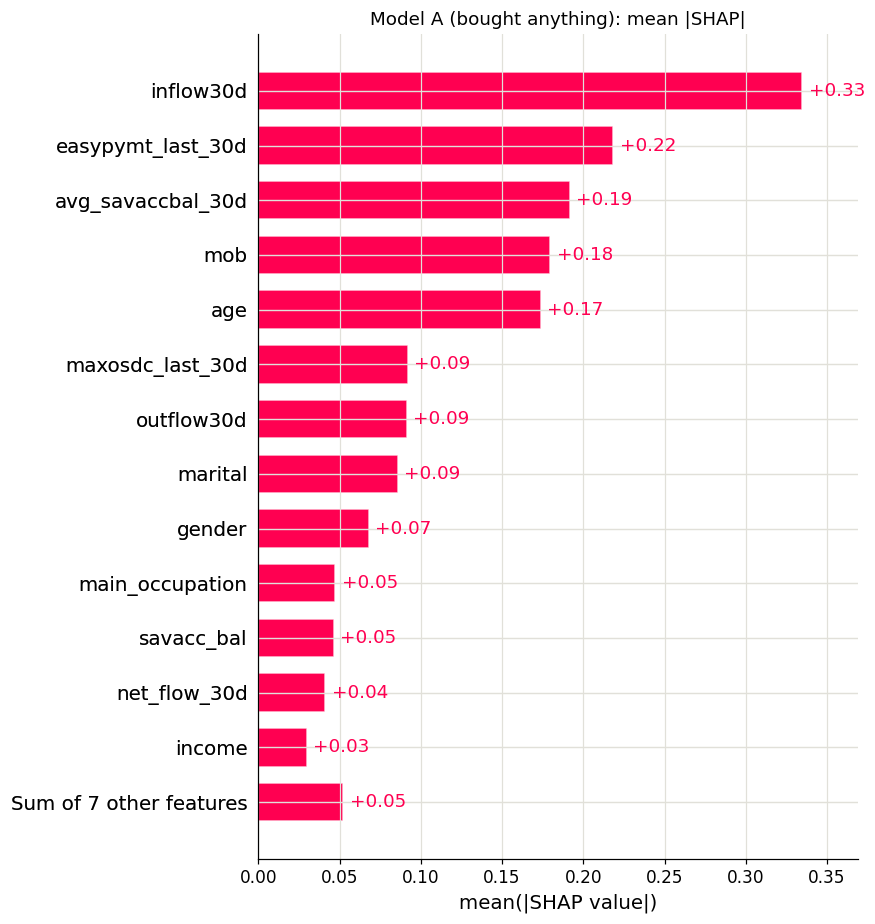

In [11]:
sample = np.random.default_rng(SEED).choice(i_test, size=20_000, replace=False)
Xsh = X.iloc[sample]

expl_bin = shap.TreeExplainer(lgb_bin)
sv_bin = expl_bin(Xsh)
if sv_bin.values.ndim == 3:  # some shap versions return both classes for binary
    sv_bin = sv_bin[:, :, 1]

fig = plt.figure(figsize=(7, 5))
shap.plots.bar(sv_bin, max_display=14, show=False)
plt.title("Model A (bought anything): mean |SHAP|"); plt.tight_layout(); plt.show()

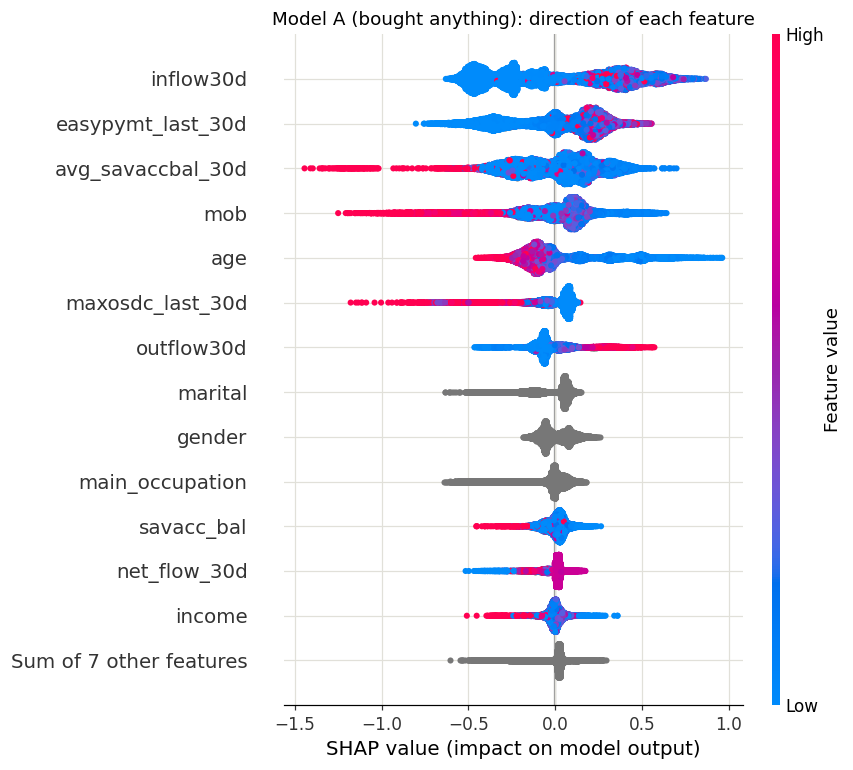

In [12]:
plt.figure(figsize=(7, 5.5))
shap.plots.beeswarm(sv_bin, max_display=14, show=False)
plt.title("Model A (bought anything): direction of each feature"); plt.tight_layout(); plt.show()

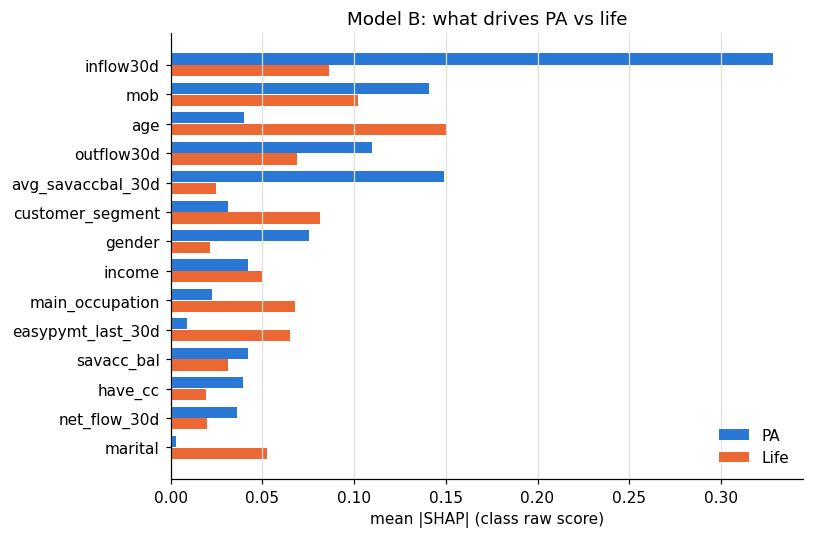

,PA,Life
inflow30d,0.328,0.086
avg_savaccbal_30d,0.149,0.025
mob,0.141,0.102
outflow30d,0.110,0.069
gender,0.075,0.021
income,0.042,0.050
savacc_bal,0.042,0.031
age,0.040,0.150
have_cc,0.040,0.019
net_flow_30d,0.036,0.020


In [13]:
expl_3 = shap.TreeExplainer(lgb_3)
sv_3 = expl_3(Xsh)          # shape: customers x features x classes
imp = pd.DataFrame({name: np.abs(sv_3.values[:, :, k]).mean(axis=0) for k, name in [(1, "PA"), (2, "Life")]},
                   index=FEATURES)
# Saved for reference (not used by the report): each feature's share of that product's total mean |SHAP|.
(imp / imp.sum() * 100).round(2).rename_axis("feature").to_csv(Path.cwd().parent / "outputs" / "shap_importance.csv")
imp = imp.loc[imp.sum(axis=1).sort_values().index].tail(14)

fig, ax = plt.subplots(figsize=(7.5, 5))
yy = np.arange(len(imp))
ax.barh(yy + 0.2, imp["PA"], height=0.38, color=PA, label="PA")
ax.barh(yy - 0.2, imp["Life"], height=0.38, color=LIFE, label="Life")
ax.set_yticks(yy); ax.set_yticklabels(imp.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("mean |SHAP| (class raw score)"); ax.set_title("Model B: what drives PA vs life"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
imp.sort_values("PA", ascending=False).round(3)

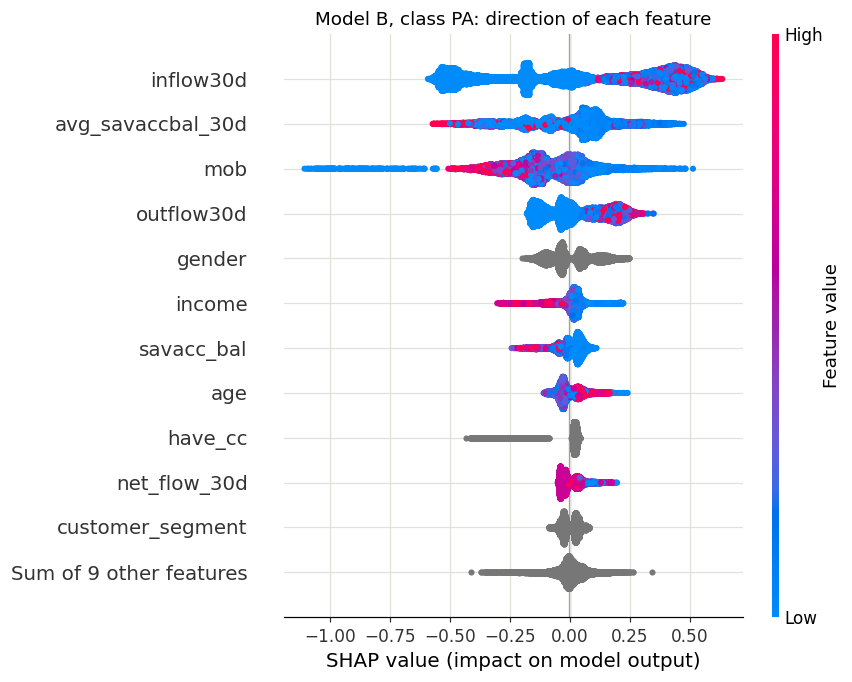

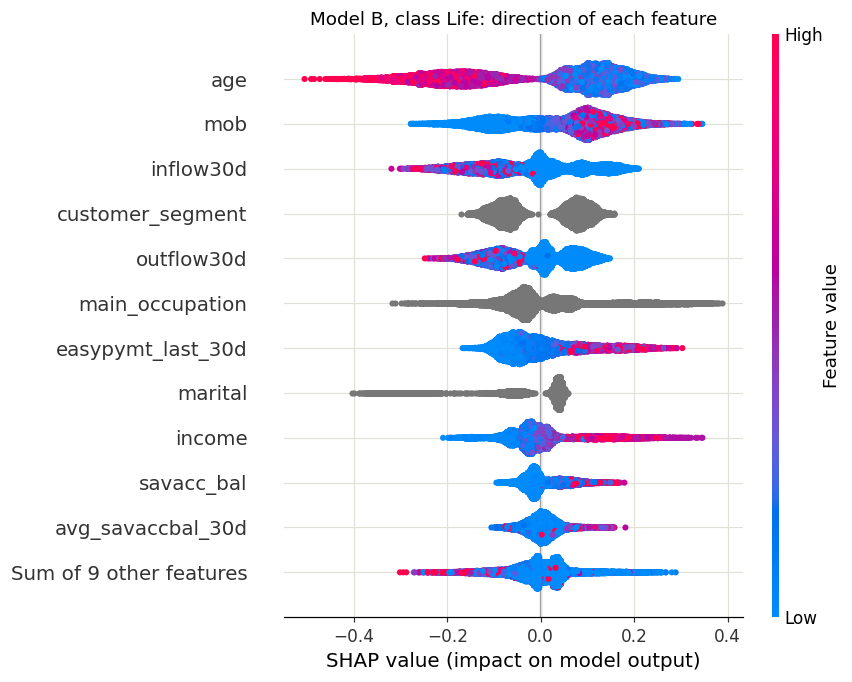

In [14]:
for k, name in [(1, "PA"), (2, "Life")]:
    plt.figure(figsize=(7, 5.5))
    shap.plots.beeswarm(sv_3[:, :, k], max_display=12, show=False)
    plt.title(f"Model B, class {name}: direction of each feature"); plt.tight_layout(); plt.show()

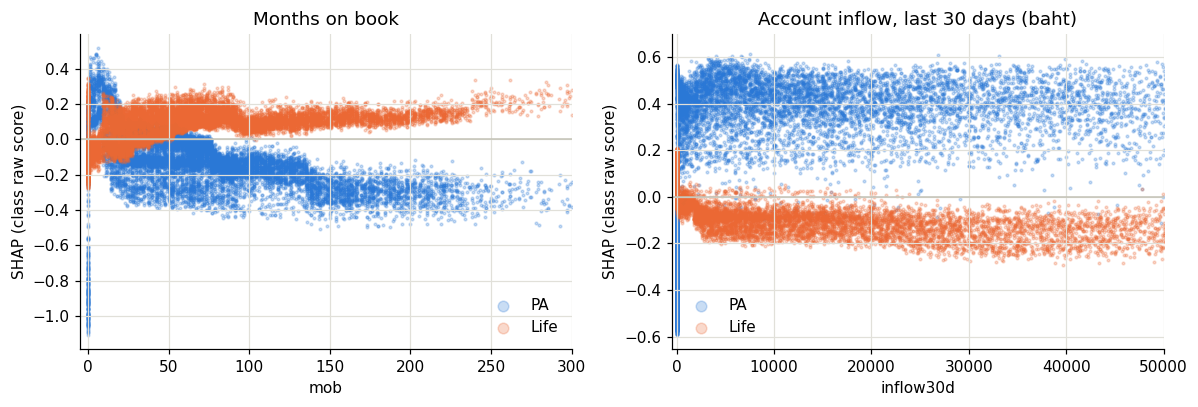

In [15]:
# Dependence on the two features the earlier analysis flagged: months on book and account inflow.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, feat, xmax in [(axes[0], "mob", 300), (axes[1], "inflow30d", 50_000)]:
    j = FEATURES.index(feat)
    xv = Xsh[feat].to_numpy(dtype=float)
    for k, name, color in [(1, "PA", PA), (2, "Life", LIFE)]:
        ax.scatter(xv, sv_3.values[:, j, k], s=3, alpha=0.25, color=color, label=name, rasterized=True)
    ax.axhline(0, color="#c3c2b7", lw=1); ax.set_xlim(-5 if feat == "mob" else -500, xmax)
    ax.set_xlabel(feat); ax.set_ylabel("SHAP (class raw score)"); ax.legend(frameon=False, markerscale=4)
axes[0].set_title("Months on book"); axes[1].set_title("Account inflow, last 30 days (baht)")
plt.tight_layout(); plt.show()

In [16]:
# The same MOB curve as a table: average SHAP per MOB group (class raw score; exp() gives a rough multiplier).
j = FEATURES.index("mob")
grp = pd.cut(Xsh["mob"], [-0.5, 0.5, 12, 60, 120, 1000], labels=["0", "1-12", "13-60", "61-120", "121+"])
tab = pd.DataFrame({"customers": grp.value_counts().sort_index(),
                    "PA mean SHAP": pd.Series(sv_3.values[:, j, 1], index=Xsh.index).groupby(grp, observed=True).mean(),
                    "Life mean SHAP": pd.Series(sv_3.values[:, j, 2], index=Xsh.index).groupby(grp, observed=True).mean()})
tab["PA odds x"] = np.exp(tab["PA mean SHAP"]); tab["Life odds x"] = np.exp(tab["Life mean SHAP"])
tab.round(2)

,customers,PA mean SHAP,Life mean SHAP,PA odds x,Life odds x
mob,,,,,
0,5203,-0.07,-0.10,0.93,0.91
1-12,866,0.18,-0.02,1.20,0.98
13-60,6642,-0.04,0.06,0.96,1.06
61-120,4645,-0.13,0.12,0.87,1.12
121+,2511,-0.27,0.13,0.76,1.14


**What SHAP shows for the class-weighted models**

Units: for Model A, SHAP is in log-odds. For Model B, it is in the class's raw score (the softmax input), so read it as the direction and relative size of an effect. Weighting shifts the baseline but keeps the directions.

**PA is driven by account behaviour** (Model B, PA plot):
- **Inflow in the last 30 days** is still by far the top driver (mean |SHAP| 0.33, twice the next one).
- It works like a switch: zero inflow sits around −0.5, any inflow sits at +0.3 to +0.6, and the amount barely matters (dependence plot).
- **High average savings balance → lower PA**, and **high income → lower PA**. **Credit-card holders** form a clear negative cluster.
- **Outflow** high → higher PA, the same activity signal.

**Life is driven by who the customer is** (Model B, life plot):
- **Age** is the top driver: young → right, older → left.
- Then **MOB** (longer tenure → more life), **customer segment**, **occupation** (a long right tail, which notebook 02 suggests is students), **payment size** (bigger → more life), **marital status** (one large negative cluster; notebook 02 shows married customers buy life less) and **income** (higher → more life).
- **Inflow and outflow point the other way for life:** high activity → slightly less life.

**The same features push PA and life in opposite directions:** inflow, outflow, income and tenure. These are two different customers.

**MOB:**
- **MOB 1–12** is still the best PA group (mean SHAP +0.18, about 1.2×), and PA falls with tenure (0.76× at 121+).
- **MOB 0** now gets a small penalty on average (−0.07), with a long negative tail down to about −1.1 for some customers. In the weighted model MOB 0 itself carries part of the "no account activity" penalty. It still does not look like a group of new customers (MOB 1–12 is clearly positive).

**Model A** (bought anything) mixes the two stories: activity features (from PA) and age (from life) at the top. High `maxosdc_last_30d` (maximum debit-card outstanding balance) now clearly lowers the score. On its own, the PA and life rates are flat across this field, so this is a conditional effect: high balances with little else going on. I'd read it together with the savings-balance features as "well-funded, inactive accounts buy less", not as a separate finding.

*Caveats:*
- SHAP explains the **model**, not the world. Big SHAP means a strong predictor, not a cause.
- Correlated features (inflow/outflow/net flow; balance/average balance/debit-card balance) **share credit**, so read them as groups.
- Grey (categorical) rows don't say which category is which. I've named clusters only where the rates in notebook 02 make it clear.

## 5. From SHAP to segments: crossing the top drivers

SHAP says PA is driven mainly by **account activity** and **MOB**, and life mainly by **age** (with income and segment). Here those drivers are crossed in plain rate tables, with no model, so the segments can be read and used directly.

**Guard against cherry-picking.** With many cells, some look good by chance. So every table is computed on two random halves of the customers (A and B). A pattern is only reported if it shows up in **both** halves. Cells with fewer than 1,000 customers are not used for claims.

In [17]:
f = df[df["has_financials"]].copy()
f["half"] = np.where(np.random.default_rng(SEED).random(len(f)) < 0.5, "A", "B")
f["mob_band"] = pd.cut(f["mob"], [-0.5, 0.5, 12, 60, 120, 1000], labels=["0", "1-12", "13-60", "61-120", "121+"])

def cross(val, a, b, data=f):
    g = data.groupby([a, b], observed=True)[val]
    return (g.mean() * 100).round(2).unstack(), g.size().unstack()

rate, n = cross("bought_pa", "mob_band", "account_active")
print("PA rate % by MOB x account activity (all customers with financials)"); display(rate); display(n)
print("Same table on each random half:")
display(f.groupby(["half", "mob_band", "account_active"], observed=True)["bought_pa"].mean().mul(100).round(2).unstack())

PA rate % by MOB x account activity (all customers with financials)


account_active,active,dormant
mob_band,,
0,0.00,0.44
1-12,2.98,0.07
13-60,1.55,0.08
61-120,1.12,0.09
121+,0.57,0.11


account_active,active,dormant
mob_band,,
0,2732,53412
1-12,4971,4593
13-60,45676,25954
61-120,34444,14635
121+,18372,7964


Same table on each random half:


account_active  active  dormant
half mob_band                  
A    0            0.00     0.39
     1-12         3.04     0.09
     13-60        1.63     0.08
     61-120       1.22     0.07
     121+         0.67     0.10
B    0            0.00     0.49
     1-12         2.91     0.04
     13-60        1.47     0.08
     61-120       1.01     0.11
     121+         0.47     0.12

In [18]:
# Adding gender (the next SHAP driver for PA) inside active accounts.
act = f[f["account_active"] == "active"]
display(cross("bought_pa", "mob_band", "gender", act)[0])

# Where the PA buyers are: share of customers vs share of PA buyers per tier.
tier = np.select([f["mob"] == 0, f["account_active"] == "dormant", f["mob"].between(1, 12), f["mob"].between(13, 60), f["mob"].between(61, 120)],
                 ["MOB 0 (suspect)", "dormant (MOB 1+)", "active, MOB 1-12", "active, MOB 13-60", "active, MOB 61-120"], "active, MOB 121+")
t = f.groupby(tier).agg(customers=("bought_pa", "size"), pa=("bought_pa", "sum"), life=("bought_life", "sum"))
t["% of customers"] = t["customers"] / t["customers"].sum() * 100
t["% of PA buyers"] = t["pa"] / t["pa"].sum() * 100
t["PA rate %"] = t["pa"] / t["customers"] * 100
t["life rate %"] = t["life"] / t["customers"] * 100
t.round(2)

gender,Female,Male
mob_band,,
0,0.00,0.00
1-12,2.33,3.77
13-60,1.17,1.98
61-120,0.86,1.50
121+,0.49,0.71


,customers,pa,life,% of customers,% of PA buyers,PA rate %,life rate %
MOB 0 (suspect),56144,234,169,26.29,14.33,0.42,0.30
"active, MOB 1-12",4971,148,21,2.33,9.06,2.98,0.42
"active, MOB 121+",18939,111,90,8.87,6.80,0.59,0.48
"active, MOB 13-60",45676,709,180,21.38,43.42,1.55,0.39
"active, MOB 61-120",34444,385,195,16.13,23.58,1.12,0.57
dormant (MOB 1+),53418,46,328,25.01,2.82,0.09,0.61


In [19]:
# Life: age x income (the top life drivers that are plain customer attributes), on each half.
display(cross("bought_life", "age_band", "income_band")[0])
display(f.groupby(["half", "age_band", "income_band"], observed=True)["bought_life"].mean().mul(100).round(2).unstack())
young_rich = (f["age"] < 40) & (f["income"] >= 30_000)
print("under 40 and income >= 30k: %d customers, life rate %.2f%% (half A %.2f%%, half B %.2f%%) vs %.2f%% overall" % (
    young_rich.sum(), f.loc[young_rich, "bought_life"].mean() * 100,
    f.loc[young_rich & (f.half == "A"), "bought_life"].mean() * 100, f.loc[young_rich & (f.half == "B"), "bought_life"].mean() * 100,
    f["bought_life"].mean() * 100))

income_band,<5k,5k-15k,15k-30k,30k-50k,50k+
age_band,,,,,
23-29,0.69,0.57,0.63,1.26,0.92
30-39,0.40,0.39,0.48,0.83,0.98
40-49,0.28,0.26,0.37,0.34,0.42
50-61,0.18,0.18,0.33,0.24,0.34


income_band     <5k  5k-15k  15k-30k  30k-50k  50k+
half age_band                                      
A    23-29     0.76    0.58     0.66     1.17  1.04
     30-39     0.43    0.41     0.50     0.89  0.64
     40-49     0.32    0.24     0.38     0.56  0.63
     50-61     0.21    0.15     0.41     0.28  0.44
B    23-29     0.63    0.57     0.60     1.35  0.80
     30-39     0.36    0.38     0.47     0.77  1.32
     40-49     0.24    0.29     0.35     0.11  0.21
     50-61     0.16    0.21     0.25     0.19  0.25

under 40 and income >= 30k: 16824 customers, life rate 0.96% (half A 0.91%, half B 1.02%) vs 0.46% overall


In [20]:
# The odd cell: MOB 0 customers WITH account activity bought no PA at all.
from scipy import stats
z = f[(f["mob"] == 0) & (f["account_active"] == "active")]
print(f"MOB 0 and active: {len(z):,} customers, {z['bought_pa'].sum()} PA buyers, {z['bought_life'].sum()} life buyers")
print("chance of 0 PA buyers if they bought at the active-account rate (1.27%%): %.1e" % stats.binom.pmf(0, len(z), 0.0127))

MOB 0 and active: 2,732 customers, 0 PA buyers, 27 life buyers
chance of 0 PA buyers if they bought at the active-account rate (1.27%): 6.8e-16


**What crossing the drivers shows**

**PA: activity × MOB is the strongest combination in the data.**
- **Active accounts opened 1–12 months ago buy PA at 2.98%**, 3.9× the PA average. It is 3.04% on half A and 2.91% on half B. For men in that group it is 3.77%.
- Within active accounts, PA falls steadily with tenure: 1.55% → 1.12% → 0.57%.
- **Dormant accounts stay near 0.1% at every tenure.** So MOB only matters once the account is active, which is the interaction the SHAP plots hinted at.
- **Where PA buyers are:** active accounts with MOB 13–120 are 37.5% of offers and hold 67% of PA buyers. Dormant accounts (MOB 1+) are 25% of offers and hold only 3% of PA buyers.

**Life: young earners, and dormant customers.**
- **Under-40s earning 30k+ buy life at 0.96%** (16,824 customers, 2.1× the life average; 0.91% and 1.02% on the two halves).
- At every income, life falls with age.
- **Dormant accounts (MOB 1+) buy life at 0.61%**, above the 0.46% average, while almost never buying PA. That supports a life-only offer for them.
- Combinations with segment or students looked good on one half and not the other, so they are **not** used.

**One more data problem.** The 2,732 MOB-0 customers with an active account bought **no PA at all**. At the active-account rate, about 35 would be expected, and the chance of seeing 0 is about 1 in 10^15. Together with the earlier MOB-0 checks, this points to these rows being joined or loaded differently. It should be raised with the data owner.

*How these segments were chosen:* only from drivers the model ranked highly, with fixed, round cut-offs, and kept only if they held on both halves. A greedy search over more conditions found bigger lifts on half A that shrank on half B, which is a reminder that small, finely cut segments overfit.

## Summary

Test PR AUC, with × random (PR AUC ÷ base rate) in brackets. LightGBM with class weighting (`scale_pos_weight` for binary, class weights for 3-class):

| | Model A: binary | Model B: 3-class |
|---|---|---|
| Any purchase (base 1.22%) | **2.59% (2.1×)** | 2.59% (2.1×), ranking by P(PA)+P(Life) |
| PA (base 0.76%) | - | **2.72% (3.6×)** |
| Life (base 0.46%) | - | **0.98% (2.1×)** |
| Same model, unweighted | 2.67% (2.2×) | PA 2.71% (3.5×) · Life 0.94% (2.0×) |
| Class-weighted logistic regression | 2.21% (1.8×) | PA 1.91% (2.5×) · Life 0.68% (1.5×) |
| Top 10% of scores | precision 3.2%, recall 26% | PA: precision 2.7%, recall 35% · Life: 0.7%, 16% |
| Says which product? | No | Yes |

**What weighting did:**
- It **did not change the ranking quality** (±0.1 percentage points PR AUC).
- It **cut overfitting** (train PR AUC 12.2% → 4.5%).
- It **inflated the probabilities**, so they can't be read as real purchase rates without recalibration.

**Recommendation: use the 3-class model.** It ranks "will buy anything" as well as the binary model, and it also says which product to offer.

**Honest limits**
- **No resampling (SMOTE or undersampling) and no hyperparameter tuning.** Weighting alone shows that the ceiling comes from the features, not from how the imbalance is handled.
- **Life is hard to predict** from these fields (2× random).
- **Random split, not time-based** (there is no year). Validate on the next campaign before using it.
- **Probabilities are not calibrated** (inflated by the weights). Use them for ranking, or recalibrate them (e.g. isotonic regression on the validation set) before reading them as rates.